# Pronóstico de horas-hombre — Entradas a almacén (Prophet)

Notebook **conciso**, enfocado en la **predicción**. Implementa las recomendaciones del análisis de
`prediccion_horas_hombre_entradas.ipynb`: pronóstico a **grano diario** (la señal sí es predecible a
ese grano), con regresores de calendario e intervalos **conformal**, y **desagregación a resolución
horaria** vía el perfil intradía. Fuente única: **API SGA** (`sga_entradas`). **Solo Prophet** (sin SARIMA).

In [1]:
import os, logging, warnings
warnings.filterwarnings("ignore")
for _n in ["cmdstanpy", "prophet"]:
    logging.getLogger(_n).setLevel(logging.CRITICAL)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from lisa_client import LisaClient, LisaAPIError
try:
    from dotenv import load_dotenv; load_dotenv()
except ImportError:
    pass

# Dark mode (consistente con el resto del repo)
plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "#111111", "axes.facecolor": "#111111",
    "savefig.facecolor": "#111111", "grid.color": "#333333", "grid.linestyle": "--",
    "axes.grid": True, "figure.figsize": (12, 4), "lines.linewidth": 1.8})

# Constantes
ALMACEN      = "5460D"
FECHA_DESDE  = "01/01/2025"     # cota inferior; el API devuelve todo lo posterior
HORIZONTE_BD = 10               # dias habiles a pronosticar (~2 semanas)
NIVEL_IC     = 0.80             # nivel de la banda conformal

## 1. Carga de datos desde el API SGA

In [2]:
client = LisaClient()
resp = client.entradas_almacen(fecha_gen=FECHA_DESDE, almacen=ALMACEN, regs=-1)
reg = resp.get("registros", {}).get("reg") or []
if isinstance(reg, dict):
    reg = [reg]
ent = pd.json_normalize(reg)
ent["fecha_inicio"] = pd.to_datetime(ent["fecha_inicio"], format="mixed", dayfirst=True, errors="coerce")

# Usuarios de negocio: excluye cuentas de sistema y nulos (mismo criterio que el notebook fuente)
SYS_USERS = {"ADMIN", "", None}
ent = ent[ent["fecha_inicio"].notna() & ent["usuario"].notna()
          & ~ent["usuario"].isin(SYS_USERS)].copy()
print(f"API sga_entradas: {len(ent):,} tareas | "
      f"{ent['fecha_inicio'].min():%d/%m/%Y} -> {ent['fecha_inicio'].max():%d/%m/%Y}")

12:59:47 [INFO] POST /galileo/lisa/geninf/isp/sga_entradas | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


API sga_entradas: 3,392 tareas | 02/01/2026 -> 22/06/2026


## 2. Preparación: serie diaria (días hábiles) + perfil intradía

Horas-hombre por hora = usuarios distintos activos en esa hora reloj. La serie **horaria** es ~86%
ceros (intermitente), pero el **total diario en días hábiles** sí es predecible. Guardamos también
el **perfil intradía** (peso de cada hora) para desagregar el pronóstico diario a resolución horaria.

In [3]:
ent["ts"] = ent["fecha_inicio"].dt.floor("h")
hh = ent.groupby("ts")["usuario"].nunique()            # horas-hombre por hora

# (rec. 1 y 7) GRANO DIARIO + REGIMEN: serie objetivo = horas-hombre por dia habil (Lun-Vie).
daily = hh.groupby(hh.index.normalize()).sum()
bdays = pd.bdate_range(daily.index.min(), daily.index.max())   # rejilla Lun-Vie continua
serie = daily.reindex(bdays, fill_value=0).astype(float)       # cierres entre semana = 0
serie.index.name = "ds"

# Perfil intradia (pesos por hora, solo Lun-Vie) para DESAGREGAR a horario
hh_wd  = hh[hh.index.dayofweek < 5]
perfil = hh_wd.groupby(hh_wd.index.hour).sum()
perfil = (perfil / perfil.sum()).reindex(range(24), fill_value=0.0)

print(f"Serie diaria habil: {len(serie)} dias | {(serie == 0).mean():.0%} ceros | "
      f"mediana(>0) = {serie[serie > 0].median():.0f} h-hombre")
print("Perfil intradia:", {h: round(float(w), 3) for h, w in perfil.items() if w > 0.01})

Serie diaria habil: 122 dias | 15% ceros | mediana(>0) = 11 h-hombre
Perfil intradia: {7: 0.024, 8: 0.092, 9: 0.124, 10: 0.127, 11: 0.116, 12: 0.124, 13: 0.091, 14: 0.08, 15: 0.096, 16: 0.082, 17: 0.02, 18: 0.01}


## 3. Recomendaciones implementadas (y validadas con backtest)

- **Grano diario + régimen (rec. 1 y 7)** — modelar el día hábil y **desagregar a hora** con el perfil intradía.
- **Regresores de calendario (rec. 4)** — efecto **quincena / cambio de mes** (~+29% observado) + festivos MX + cierres observados. Es lo que más baja el error.
- **Intervalo conformal (rec. 5)** — el IC nativo **sub-cubre**; se calibra con los cuantiles de los residuos del backtest de origen móvil.
- **`log1p` y *cap* de outliers: probados y descartados** — a grano diario `log1p` **aumenta el sesgo conservador** (sub-estima) y el *cap* no cambia nada (no hay cola pesada).

In [4]:
# (rec. 4) Regresores de calendario (conocidos a futuro): quincena / cambio de mes
def calendario(idx):
    dom = idx.day
    return pd.DataFrame({
        "mid_mes":  ((dom >= 12) & (dom <= 18)).astype(float),   # pico de mediados de mes
        "turn_mes": ((dom >= 28) | (dom <= 2)).astype(float),    # cambio de mes
    }, index=idx)

# Prophet aditivo SIN log1p: estacionalidad semanal + festivos MX + cierres observados + calendario.
def ajustar(tr):
    m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                seasonality_mode="additive", interval_width=NIVEL_IC)
    cierres = tr.index[tr.values == 0]
    if len(cierres):
        m.holidays = pd.DataFrame({"holiday": "cierre", "ds": cierres,
                                   "lower_window": 0, "upper_window": 0})
    try:
        m.add_country_holidays(country_name="MX")
    except Exception:
        pass
    for c in ["mid_mes", "turn_mes"]:
        m.add_regressor(c)
    dfp = pd.concat([pd.DataFrame({"ds": tr.index, "y": tr.values}),
                     calendario(tr.index).reset_index(drop=True)], axis=1)
    m.fit(dfp)
    return m

def pronosticar(m, idx):
    fdf = pd.concat([pd.DataFrame({"ds": idx}), calendario(idx).reset_index(drop=True)], axis=1)
    return m.predict(fdf).set_index("ds")["yhat"].clip(lower=0)

## 4. Validación (origen móvil) y calibración del intervalo conformal

Backtest de origen móvil (reajuste por fold). El error y el *skill* se reportan sobre **días con
carga** (`y>0`), consistente con el MAPE y con lo que importa para planear personal. La banda
**conformal** se calibra con los cuantiles de los residuos.

In [5]:
# (rec. 5) Backtest de origen movil + banda CONFORMAL (cuantiles de residuos).
H, STEP, N_FOLDS = HORIZONTE_BD, 5, 6
n = len(serie)
origins = [o for o in [n - H - k * STEP for k in range(N_FOLDS)][::-1] if o >= 60]
if not origins:
    raise ValueError(f"Historia insuficiente para backtest: {n} dias habiles (se requieren >= {H + 60}).")

err_op, ape, resid, enaive_op = [], [], [], []
for o in origins:
    tr, te = serie.iloc[:o], serie.iloc[o:o + H]
    yhat = pronosticar(ajustar(tr), te.index).values
    e = te.values - yhat                                  # residuo = real - pronostico
    # naive estacional SIN fuga: repite la ultima semana habil ANTERIOR al origen
    base = serie.iloc[o - 5:o].values                     # 5 dias habiles = semana previa (Lun-Vie)
    nv = base[np.arange(len(te)) % 5]
    op = te.values > 0                                    # metricas solo en dias con carga
    err_op += list(e[op]); enaive_op += list((nv - te.values)[op]); resid += list(e[op])
    ape += list(np.abs(e[op] / te.values[op]))

rmse  = np.sqrt(np.mean(np.square(err_op)))
mae   = np.mean(np.abs(err_op))
mape  = np.mean(ape) * 100 if ape else float("nan")
skill = 1 - rmse / np.sqrt(np.mean(np.square(enaive_op)))
alpha = (1 - NIVEL_IC) / 2
q_lo, q_hi = np.quantile(resid, [alpha, 1 - alpha])       # banda conformal aditiva
print(f"Backtest ({len(origins)} folds, H={H}d, dias con carga): "
      f"RMSE={rmse:.1f}  MAE={mae:.1f}  MAPE={mape:.0f}%  skill vs naive={skill:+.2f}")
print(f"Banda conformal {int(NIVEL_IC * 100)}%: [{q_lo:+.1f}, {q_hi:+.1f}] h-hombre alrededor del punto")

Backtest (6 folds, H=10d, dias con carga): RMSE=15.1  MAE=11.0  MAPE=134%  skill vs naive=+0.41
Banda conformal 80%: [-9.3, +27.8] h-hombre alrededor del punto


## 5. Modelo final, pronóstico diario y desagregación a horario

In [6]:
# Modelo final sobre toda la serie + pronostico de HORIZONTE_BD dias habiles
modelo = ajustar(serie)
futuro_idx  = pd.bdate_range(serie.index.max() + pd.Timedelta(days=1), periods=H)
pred_dia    = pronosticar(modelo, futuro_idx)
pred_dia_lo = (pred_dia + q_lo).clip(lower=0)
pred_dia_hi = (pred_dia + q_hi).clip(lower=0)

# (rec. 1) Desagregacion a hora: horas-hombre por hora = pronostico diario x perfil intradia
def a_horario(serie_dia):
    filas = {d + pd.Timedelta(hours=int(h)): val * w
             for d, val in serie_dia.items() for h, w in perfil.items() if w > 0}
    return pd.Series(filas).sort_index()

pred_hora, pred_hora_lo, pred_hora_hi = map(a_horario, [pred_dia, pred_dia_lo, pred_dia_hi])
print(f"Pronostico {futuro_idx[0]:%d/%m} -> {futuro_idx[-1]:%d/%m} | "
      f"{pred_dia.sum():.0f} h-hombre en {H} dias habiles")

Pronostico 23/06 -> 06/07 | 125 h-hombre en 10 dias habiles


## 6. Predicción vs. toda la línea de tiempo (diario)

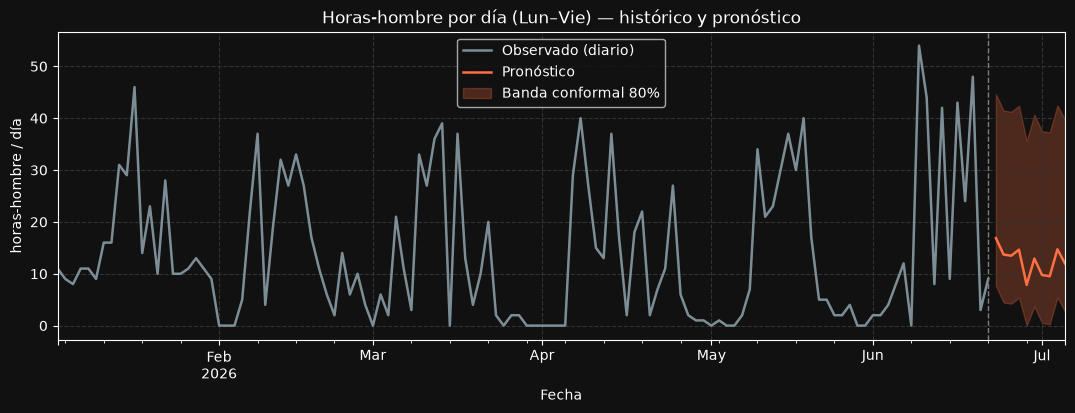

In [7]:
fig, ax = plt.subplots(figsize=(13, 4))
serie.plot(ax=ax, label="Observado (diario)", color="#90A4AE", alpha=0.85)
pred_dia.plot(ax=ax, label="Pronóstico", color="#FF7043")
ax.fill_between(pred_dia.index, pred_dia_lo, pred_dia_hi, color="#FF7043", alpha=0.25,
                label=f"Banda conformal {int(NIVEL_IC * 100)}%")
ax.axvline(serie.index.max(), color="gray", ls="--", lw=1)
ax.set_title("Horas-hombre por día (Lun–Vie) — histórico y pronóstico")
ax.set_xlabel("Fecha"); ax.set_ylabel("horas-hombre / día"); ax.legend()
plt.show()

## 7. Zoom — últimas 2 semanas y predicción (resolución horaria)

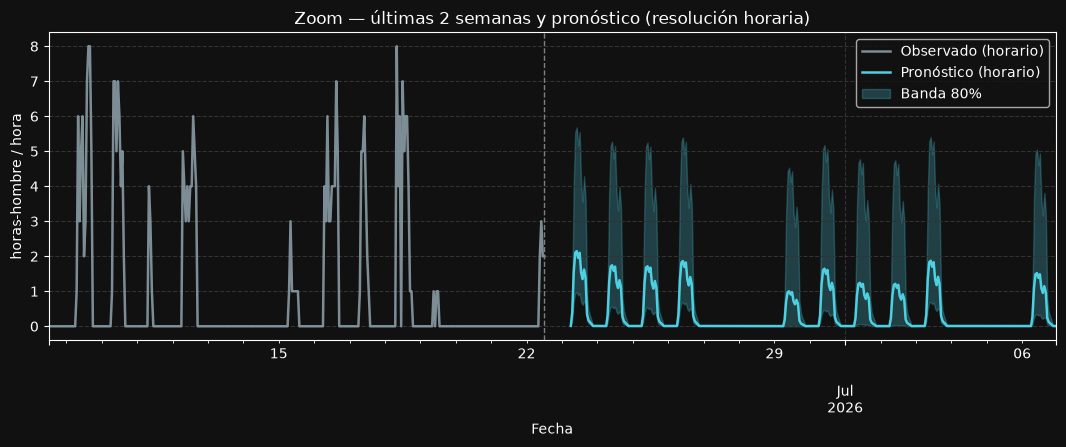

In [8]:
# Historico horario continuo (solo se usa aqui, para el zoom)
grid_h = pd.date_range(hh.index.min().floor("D"), hh.index.max(), freq="h")
serie_hora = hh.reindex(grid_h, fill_value=0).astype(float)

ini = serie_hora.index.max() - pd.Timedelta(days=14)     # 2 semanas calendario
fig, ax = plt.subplots(figsize=(13, 4))
serie_hora.loc[ini:].plot(ax=ax, label="Observado (horario)", color="#90A4AE", alpha=0.85)
pred_hora.plot(ax=ax, label="Pronóstico (horario)", color="#4DD0E1")
ax.fill_between(pred_hora.index, pred_hora_lo, pred_hora_hi, color="#4DD0E1", alpha=0.25,
                label=f"Banda {int(NIVEL_IC * 100)}%")
ax.axvline(serie.index.max() + pd.Timedelta(hours=12), color="gray", ls="--", lw=1)
ax.set_title("Zoom — últimas 2 semanas y pronóstico (resolución horaria)")
ax.set_xlabel("Fecha"); ax.set_ylabel("horas-hombre / hora"); ax.legend()
plt.show()